<a href="https://colab.research.google.com/github/Morteza-Porabdolahi/AI_projects/blob/main/yolov8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install roboflow

from roboflow import Roboflow
rf = Roboflow(api_key="moD8XngJfumsdxMbd9iJ")
project = rf.workspace("roboflow-100").project("vehicles-q0x2v")
version = project.version(1)
dataset = version.download("yolov8")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 98.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 7.5 MB/s eta 0:00:00
  Attempting uninstall: typer
    Found existing installation: typer 0.27.3
    Uninstalling typer-0.27.3:
      Successfully uninstalled typer-0.27.3
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to vehicles-1 in yolov8:: 100%|██████████| 8128/8128 [00:01<00:00, 6949.29it/s]


In [ ]:
import glob, os

ROOT = '/content/vehicles-1'

print('Number of images per train, test and validation: ')
for folder in os.listdir(ROOT):
  if os.path.isdir(f'{ROOT}/{folder}'):
    print(
        f'{folder}: {len(os.listdir(os.path.join(ROOT, folder, 'images')))}'
    )

Number of images per train, test and validation: 
valid: 966
test: 458
train: 2634


In [ ]:
# An example of a label file associated with an image
# cls_id cx cy width height
train_annotations = glob.glob(f'{ROOT}/train/labels/*.txt')
print(open(train_annotations[0]).read())

10 0.34765625 0.378125 0.0421875 0.05625
9 0.55546875 0.43203125 0.0515625 0.09375
4 0.36484375 0.43359375 0.0421875 0.05
4 0.5125 0.49375 0.053125 0.07109375
11 0.64453125 0.54921875 0.1421875 0.23515625
4 0.75859375 0.584375 0.0921875 0.13515625
4 0.67890625 0.86875 0.1453125 0.24140625


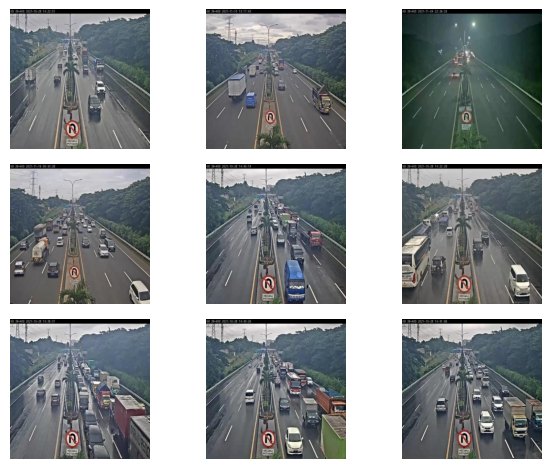

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import random

train_images = glob.glob(f'{ROOT}/train/images/*.jpg')
figure, axes = plt.subplots(3, 3)

for ax, name in zip(axes.ravel(), random.sample(train_images, 9)):
  im = Image.open(name)
  ax.imshow(im)
  ax.set_axis_off()

plt.tight_layout()
plt.show()

In [ ]:
!pip install "ultralytics<=8.3.40"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 898.5/898.5 kB 21.3 MB/s eta 0:00:00


In [ ]:
from ultralytics import YOLO

model = YOLO('yolov8n.pt', task="detect", verbose=True)

train_results = model.train(
    data=f'{dataset.location}/data.yaml',
    epochs=10,
    hsv_h=0.0,
    hsv_s=0.0,
    hsv_v=0.0,
    translate=0.0,
    scale=0.0,
    fliplr=0.0,
    mosaic=0.0,
    erasing=0.0,
    auto_augment=None,
)

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


100%|██████████| 6.25M/6.25M [00:00<00:00, 107MB/s]


New https://pypi.org/project/ultralytics/8.4.184 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.40 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: task=detect, mode=train, model=yolov8n.pt, data=/content/vehicles-1/data.yaml, epochs=10, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_fr

100%|██████████| 755k/755k [00:00<00:00, 26.2MB/s]


Overriding model.yaml nc=80 with nc=12

                   from  n    params  module                                       arguments                     
  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 
  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                
  2                  -1  1      7360  ultralytics.nn.modules.block.C2f             [32, 32, 1, True]             
  3                  -1  1     18560  ultralytics.nn.modules.conv.Conv             [32, 64, 3, 2]                
  4                  -1  2     49664  ultralytics.nn.modules.block.C2f             [64, 64, 2, True]             
  5                  -1  1     73984  ultralytics.nn.modules.conv.Conv             [64, 128, 3, 2]               
  6                  -1  2    197632  ultralytics.nn.modules.block.C2f             [128, 128, 2, True]           
  7                  -1  1    295424  ultralytic

...

       9/10      2.21G     0.7598     0.5401     0.9088        115        640: 100%|██████████| 165/165 [00:26<00:00,  6.23it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 31/31 [00:07<00:00,  3.96it/s]


                   all        966      13450      0.424      0.491      0.368      0.248

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


      10/10      2.22G     0.7044     0.5119      0.893        126        640: 100%|██████████| 165/165 [00:26<00:00,  6.24it/s]
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 31/31 [00:07<00:00,  3.96it/s]


                   all        966      13450      0.448      0.506      0.381      0.256

10 epochs completed in 0.101 hours.
Optimizer stripped from runs/detect/train/weights/last.pt, 6.2MB
Optimizer stripped from runs/detect/train/weights/best.pt, 6.2MB

Validating runs/detect/train/weights/best.pt...
Ultralytics 8.3.40 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 168 layers, 3,007,988 parameters, 0 gradients, 8.1 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95):  65%|██████▍   | 20/31 [00:09<00:03,  3.41it/s]

In [ ]:
import pandas as pd

CLASSES = train_results.names
print(CLASSES)

# Training and validation results
df = pd.read_csv('/content/runs/detect/train/results.csv')
print(df)

In [ ]:
results_image = Image.open('/content/runs/detect/train/results.png')

plt.figure(figsize=(20,8))
fig = plt.imshow(results_image)
fig.axes.set_axis_off()

In [ ]:
confusion_matrix = Image.open('/content/runs/detect/train/confusion_matrix.png')

plt.figure(figsize=(20,8))
fig = plt.imshow(confusion_matrix)
fig.axes.set_axis_off()

In [ ]:
true_labels = Image.open('/content/runs/detect/train/val_batch0_labels.jpg')
pred_labels = Image.open('/content/runs/detect/train/val_batch0_pred.jpg')

fig, axes = plt.subplots(2,1)
fig.set_figwidth(20)
fig.set_figheight(20)

axes[0].imshow(true_labels)
axes[0].set_axis_off()
axes[0].set_title('True Labels')

axes[1].imshow(pred_labels)
axes[1].set_axis_off()
axes[1].set_title('Predicted Labels')

plt.tight_layout(pad=2)


In [ ]:
validation_results = model.val()

In [ ]:
results = model.predict(source=f"{ROOT}/test/images")

In [ ]:
import matplotlib.patches as patches

random_result = random.sample(results, 1)[0]
random_result_img = Image.open(random_result.path)

fig, ax = plt.subplots(1,1,figsize=(20,8))
ax.imshow(random_result_img)
boxes = random_result.boxes

for box in boxes:
  box_cls = box.cls[0].item()

  xmin, ymin, _, _ = box.xyxy[0].tolist()
  _, _, w, h = box.xywh[0].tolist()

  ax.add_patch(patches.Rectangle((xmin,ymin), w, h, fill=False, edgecolor='red', linewidth=2))
  ax.text(xmin, ymin - 3, CLASSES[box_cls], color="white")

In [ ]:
pred_confusion_matrix = Image.open('/content/runs/detect/train2/confusion_matrix.png')

plt.figure(figsize=(20,8))
fig = plt.imshow(pred_confusion_matrix)
fig.axes.set_axis_off()

In [ ]:
ROOT_PATH = "/content/runs/detect/train2"
pred_curves = [f'{ROOT_PATH}/F1_curve.png', f'{ROOT_PATH}/PR_curve.png', f'{ROOT_PATH}/P_curve.png', f'{ROOT_PATH}/R_curve.png']

fig, axes = plt.subplots(2,2, figsize=(25,15))

for ax, path in zip(axes.ravel(), pred_curves):
  im = Image.open(path)
  ax.set_axis_off()
  ax.imshow(im)

plt.tight_layout(pad=0)

In [ ]:
from google.colab import files

files.download('/content/runs/detect/train/weights/best.pt')